# Advection–diffusion and Fourier modes

**Source:** CompSci §§3.3–3.3.2, pp. 18–21 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For constant velocity $u$ and diffusivity $D$, use flux $uc-Dc_x$ in the conservation law to obtain $c_t+uc_x=Dc_{xx}$. Set $x^*=x/L$, $t^*=t|u|/L$ and $c^*=c/C_0$ for nonzero $u$. The diffusion coefficient becomes $1/\mathrm{Pe}$, where $\mathrm{Pe}=|u|L/D$; the advection coefficient is $\operatorname{sgn}u$. Small Pe means diffusion dominates on scale $L$. For periodic boundaries the mean is conserved and $\frac{d}{dt}\frac12\int c^2dx=-D\int c_x^2dx$ by integration by parts.

For wave number $k=2\pi m/L$, substituting $\hat c_k(t)e^{ikx}$ yields $\hat c_k'=(-Dk^2-iuk)\hat c_k$. Its modulus decays and its phase shifts; the constant mode is unchanged.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


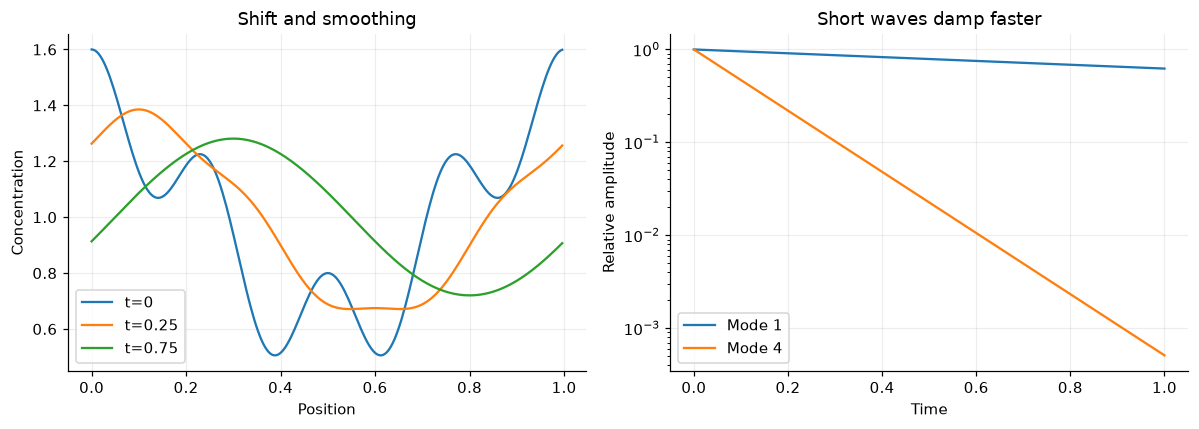

In [2]:
L=1.; u=.4; D=.012
x=np.linspace(0,L,256,endpoint=False); t=np.linspace(0,1,150)
k=2*np.pi*np.array([1,4])/L
def profile(t):
    return 1+sum(a*np.exp(-D*q*q*t)*np.cos(q*(x-u*t)) for a,q in zip([.4,.2],k))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for ts in [0,.25,.75]: ax[0].plot(x,profile(ts),label=f"t={ts}")
ax[0].set(xlabel="Position",ylabel="Concentration",title="Shift and smoothing"); ax[0].legend()
for m,q in zip([1,4],k): ax[1].semilogy(t,np.exp(-D*q*q*t),label=f"Mode {m}")
ax[1].set(xlabel="Time",ylabel="Relative amplitude",title="Short waves damp faster"); ax[1].legend()
show(fig,"03-fourier")
assert np.allclose([profile(ts).mean() for ts in t],1)
assert np.all(np.diff([np.mean(profile(ts)**2) for ts in t])<=0)
assert np.isclose(abs(np.fft.rfft(profile(.25))[4]/np.fft.rfft(profile(0))[4]),np.exp(-D*k[1]**2*.25))

## Worked exercise

**What changes for pure advection?** With $D=0$, every Fourier modulus is constant and the profile translates as $c_0(x-ut)$. Pe based on a nonzero diffusivity is then replaced by the pure transport limit.